🗺️ GENERATING COMPLETE 4-PANEL FIGURE 3 (ESTABLISHMENT YEAR + DUAL-AXIS INSETS)


C:\Users\walcker\AppData\Local\Temp\ipykernel_5656\3237997886.py:752: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


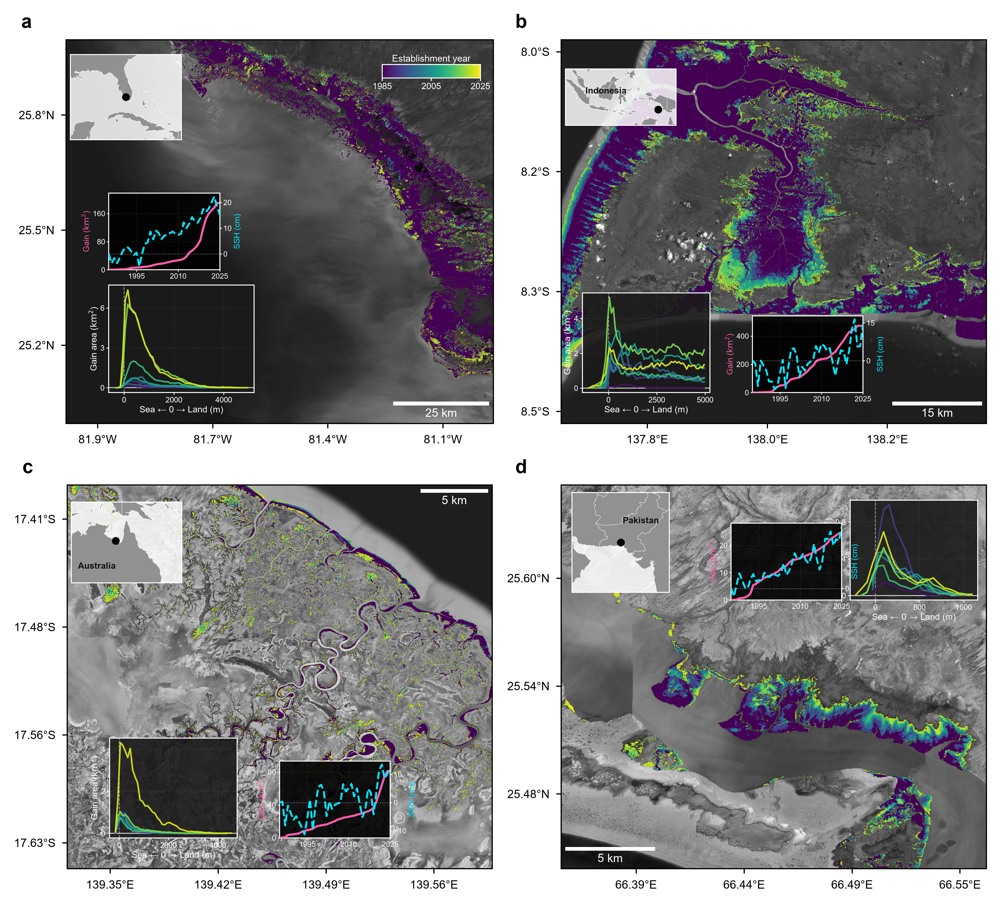

🎉 Complete 4-panel Figure 3 with gain/SSH dual-axis insets saved to: D:\MANGROVES\Research_Article_Clean\Figure3\figure3.tif


In [22]:
"""
================================================================================
SCRIPT NAME: Figure 3 (Establishment Year Rasters + Gain/SSH Dual-Axis Insets)

AUTHOR: R. Walcker, CRBE
================================================================================
"""

from pathlib import Path
import warnings
import cartopy.crs as ccrs  # noqa: F401
import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
from pyproj import Transformer
import rasterio
from rasterio.warp import Resampling, reproject
from scipy.ndimage import distance_transform_edt
from shapely.geometry import Point

try:
    from matplotlib_scalebar.scalebar import ScaleBar
    SCALEBAR_AVAILABLE = True
except ImportError:
    SCALEBAR_AVAILABLE = False

try:
    import contextily as cx
    CONTEXTILY_AVAILABLE = True
except ImportError:
    CONTEXTILY_AVAILABLE = False

# Suppress runtime and NumPy 2.5 deprecation warnings during raster reading/masking
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

# ==========================================
# 1. PATHS & CONFIGURATION
# ==========================================
OUT_DIR = Path(r"D:\MANGROVES\Research_Article_Clean\Figure3")
GAIN_AGE_DIR = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\Mangrove_Age_2025_Rasters")
GSW_BASELINE_DIR = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\GSW_1984_baseline")
SHP_VAL_PATH = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\gmwv4_mask_anthropogenic_validation.shp")
CSV_MSL_PATH = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\ecmwf_msl_annual_1deg_tiles.csv")

WORLD_BOUNDARIES_PATH = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\world-administrative-boundaries.shp")
RASTER_STACK_DIR = Path(r"D:\MANGROVES\GMW\V4\gmw_mng_ext_v4112_stack\reprojected_54034")

OUT_DIR.mkdir(parents=True, exist_ok=True)

PIXEL_AREA_KM2 = (29.869 ** 2) / 1e6
REFERENCE_YEAR = 2025
MIN_EST_YEAR = 1985
MAX_EST_YEAR = 2025

# Cross-shore gain profile parameters (matching Figure 1 Panel d, gains only)
EXCLUDE_GAIN_AGE = 41
AGE_BIN_SIZE = 5
GSW_WATER_VALUE = 1
MAX_SEA_DIST = 20000.0  # m (seaward -> negative)
MAX_LAND_DIST = 5000.0  # m (landward -> positive)
DIST_BIN_SIZE = 100.0   # m

dist_edges = np.arange(-MAX_SEA_DIST, MAX_LAND_DIST + DIST_BIN_SIZE, DIST_BIN_SIZE)
dist_centers = (dist_edges[:-1] + dist_edges[1:]) / 2.0

# Viridis: dark (older years, ~1985) -> yellow (recent years, ~2025), matching map colors
EST_YEAR_CMAP_NAME = "viridis"
est_year_cmap = plt.get_cmap(EST_YEAR_CMAP_NAME)
est_year_norm = mcolors.Normalize(vmin=MIN_EST_YEAR, vmax=MAX_EST_YEAR)

COLOR_GAIN_AXIS = "#FF5CA8"  # Pink for gained mangrove area
COLOR_SSH_AXIS = "#00E5FF"   # Cyan for relative SSH

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "mathtext.fontset": "dejavusans",
    "axes.linewidth": 0.6,
    "font.size": 7.0,
    "axes.labelsize": 7.0,
    "axes.titlesize": 8.0,
    "xtick.labelsize": 6.0,
    "ytick.labelsize": 6.0,
})

print("=" * 80)
print("🗺️ GENERATING COMPLETE 4-PANEL FIGURE 3 (ESTABLISHMENT YEAR + DUAL-AXIS INSETS)")
print("=" * 80)

# Load SSH/MSL Data globally
df_msl_all = None
if CSV_MSL_PATH.exists():
    try:
        df_msl_all = pd.read_csv(CSV_MSL_PATH, sep=";")
        if len(df_msl_all.columns) == 1:
            df_msl_all = pd.read_csv(CSV_MSL_PATH, sep=",")
        df_msl_all["tile_id"] = df_msl_all["tile_id"].astype(str).str.strip()
        df_msl_all["year"] = pd.to_numeric(df_msl_all["year"], errors="coerce")
        if "SSH_m" in df_msl_all.columns:
            df_msl_all["SSH_m"] = pd.to_numeric(df_msl_all["SSH_m"], errors="coerce")
    except Exception as e:
        print(f"⚠️ Could not load SSH CSV: {e}")

fig, axes = plt.subplots(2, 2, figsize=(7.2, 6.5), dpi=600)
transformer = Transformer.from_crs("ESRI:54034", "EPSG:4326", always_xy=True)

ax_w_in, ax_h_in = 3.1, 2.8


def _age_to_establishment_year(age_arr: np.ndarray, nodata_val: float | None) -> np.ma.MaskedArray:
    """Convert 2025 mangrove age into establishment year (2025 - age) with invalid values masked."""
    arr_float = age_arr.astype(float)
    invalid_mask = ~np.isfinite(arr_float) | (arr_float < 0)
    if nodata_val is not None and np.isfinite(nodata_val):
        invalid_mask |= np.isclose(arr_float, float(nodata_val))

    est_year = np.where(invalid_mask, np.nan, REFERENCE_YEAR - arr_float)
    return np.ma.masked_invalid(est_year)


def _plot_establishment_year_raster(ax_target, tile_id: str) -> object:
    """Plot mangrove establishment year raster (viridis: dark=older, yellow=recent)."""
    raster_matches = list(GAIN_AGE_DIR.glob(f"*{tile_id}*.tif"))
    im_handle = None
    if raster_matches:
        with rasterio.open(raster_matches[0]) as src_age:
            age_arr = np.asarray(src_age.read(1))
            nodata_age = src_age.nodatavals[0] if src_age.nodatavals else None
            est_year_masked = _age_to_establishment_year(age_arr, nodata_age)
            bounds_age = src_age.bounds
            im_handle = ax_target.imshow(
                est_year_masked,
                extent=[bounds_age.left, bounds_age.right, bounds_age.bottom, bounds_age.top],
                cmap=est_year_cmap,
                norm=est_year_norm,
                zorder=2,
                origin="upper",
            )
    return im_handle


def _find_tile_raster(directory: Path, prefixes: list[str], tile_id: str) -> Path | None:
    for pref in prefixes:
        candidate = directory / f"{pref}{tile_id}.tif"
        if candidate.exists():
            return candidate
    matches = sorted(directory.glob(f"*{tile_id}*.tif"))
    return matches[0] if matches else None


def _find_gsw_baseline(directory: Path, tile_id: str) -> Path | None:
    matches = sorted(directory.glob(f"*JRC_Yearly_{tile_id}_baseline_water*.tif"))
    if matches:
        return matches[0]
    matches = sorted(directory.glob(f"*{tile_id}*baseline_water*.tif"))
    return matches[0] if matches else None


def _age_to_five_year_period(age_clean: np.ndarray) -> np.ndarray:
    """Map age in 2025 to 5-year periods with 2020-2025 as the most recent period."""
    yr_start = np.where(
        age_clean <= AGE_BIN_SIZE,
        2020,
        REFERENCE_YEAR - (((age_clean - 1) // AGE_BIN_SIZE) * AGE_BIN_SIZE + AGE_BIN_SIZE),
    )
    yr_end = np.where(yr_start == 2020, REFERENCE_YEAR, yr_start + AGE_BIN_SIZE - 1)
    return np.array([f"{ys}-{ye}" for ys, ye in zip(yr_start, yr_end)], dtype=object)


def compute_cross_shore_gain_profiles(
    tile_ids: list[str],
) -> tuple[dict[str, np.ndarray], dict[int, float]]:
    """Compute cross-shore gain (+km²) binned profiles and annual gain area (km²) across tiles."""
    gain_by_per: dict[str, np.ndarray] = {}
    gain_by_year: dict[int, float] = {
        yr: 0.0 for yr in range(MIN_EST_YEAR, MAX_EST_YEAR + 1)
    }

    for tile_id in tile_ids:
        gain_path = _find_tile_raster(GAIN_AGE_DIR, ["mangrove_age_2025_", "gain_age_2025_"], tile_id)
        gsw_path = _find_gsw_baseline(GSW_BASELINE_DIR, tile_id)

        if gain_path is None or gsw_path is None:
            continue

        with rasterio.open(gain_path) as ref_src:
            ref_shape = (ref_src.height, ref_src.width)
            ref_crs = ref_src.crs
            ref_transform = ref_src.transform
            px_w = abs(ref_transform.a)
            px_h = abs(ref_transform.e)
            gain_arr = np.asarray(ref_src.read(1))
            gain_nodata = ref_src.nodata

        px_area_tile = (px_w * px_h) / 1e6 if (px_w > 0 and px_h > 0) else PIXEL_AREA_KM2

        with rasterio.open(gsw_path) as gsw_src:
            gsw_aligned = np.zeros(ref_shape, dtype=np.float32)
            reproject(
                source=rasterio.band(gsw_src, 1),
                destination=gsw_aligned,
                src_transform=gsw_src.transform,
                src_crs=gsw_src.crs,
                src_nodata=gsw_src.nodata,
                dst_transform=ref_transform,
                dst_crs=ref_crs,
                dst_nodata=0,
                resampling=Resampling.nearest,
            )

        is_water = gsw_aligned == GSW_WATER_VALUE
        is_land = ~is_water
        del gsw_aligned

        if np.any(is_water) and np.any(is_land):
            dist_to_land_m = distance_transform_edt(~is_land, sampling=(px_h, px_w))
            dist_to_sea_m = distance_transform_edt(~is_water, sampling=(px_h, px_w))
            signed_dist_m = np.where(is_land, dist_to_sea_m, -dist_to_land_m)
        elif np.any(is_land):
            signed_dist_m = distance_transform_edt(~is_land, sampling=(px_h, px_w))
        else:
            signed_dist_m = -distance_transform_edt(~is_water, sampling=(px_h, px_w))

        del is_water, is_land
        in_dist_range = (
            np.isfinite(signed_dist_m)
            & (signed_dist_m >= -MAX_SEA_DIST)
            & (signed_dist_m <= MAX_LAND_DIST)
        )

        valid_gain = (
            np.isfinite(gain_arr)
            & (gain_arr >= 0)
            & (gain_arr != EXCLUDE_GAIN_AGE)
            & in_dist_range
        )
        if gain_nodata is not None:
            valid_gain &= gain_arr != gain_nodata

        if np.any(valid_gain):
            gain_age_clean = gain_arr[valid_gain].astype(int)
            gain_dist_clean = signed_dist_m[valid_gain]
            gain_periods = _age_to_five_year_period(gain_age_clean)
            for per_label in np.unique(gain_periods):
                dists_p = gain_dist_clean[gain_periods == per_label]
                weights_p = np.full(len(dists_p), px_area_tile, dtype=float)
                area_bins, _ = np.histogram(dists_p, bins=dist_edges, weights=weights_p)
                if per_label not in gain_by_per:
                    gain_by_per[per_label] = np.zeros_like(area_bins)
                gain_by_per[per_label] += area_bins

            est_years = np.rint(REFERENCE_YEAR - gain_age_clean).astype(int)
            in_years = (est_years >= MIN_EST_YEAR) & (est_years <= MAX_EST_YEAR)
            if np.any(in_years):
                yr_counts, _ = np.histogram(
                    est_years[in_years],
                    bins=np.arange(MIN_EST_YEAR, MAX_EST_YEAR + 2),
                )
                for yr_idx, yr in enumerate(range(MIN_EST_YEAR, MAX_EST_YEAR + 1)):
                    gain_by_year[yr] += float(yr_counts[yr_idx]) * px_area_tile

        del gain_arr, valid_gain, signed_dist_m, in_dist_range

    return gain_by_per, gain_by_year


def _period_to_map_color(period_label: str) -> tuple:
    """Map a period string like '2020-2025' to the exact viridis color used on the map."""
    parts = period_label.split("-")
    ys, ye = int(parts[0]), int(parts[1])
    est_year_mid = 0.5 * (ys + ye)
    return est_year_cmap(est_year_norm(est_year_mid))


def plot_cross_shore_inset(
    ax_map,
    tile_ids: list[str],
    bbox_inset: list[float],
    precomputed: tuple[dict[str, np.ndarray], dict[int, float]] | None = None,
):
    """Plot gain-only cross-shore profiles in an inset using map establishment-year colors."""
    gain_by_per, _ = (
        precomputed if precomputed is not None else compute_cross_shore_gain_profiles(tile_ids)
    )
    gain_labels = sorted(gain_by_per.keys(), key=lambda s: int(s.split("-")[0]))

    ax_cs = ax_map.inset_axes(bbox_inset)
    ax_cs.set_facecolor("#1A1A1A")
    ax_cs.patch.set_alpha(0.90)
    for spine in ax_cs.spines.values():
        spine.set_linewidth(0.5)
        spine.set_color("white")

    for per_label in gain_labels:
        area_bins = gain_by_per[per_label]
        valid = area_bins > 0
        if np.any(valid):
            ax_cs.plot(
                dist_centers[valid],
                area_bins[valid],
                color=_period_to_map_color(per_label),
                linestyle="-",
                linewidth=0.8,
                alpha=0.95,
                zorder=2,
            )

    ax_cs.axhline(0, color="white", linestyle="-", linewidth=0.5, alpha=0.8, zorder=1.1)
    ax_cs.axvline(0, color="white", linestyle="--", linewidth=0.4, alpha=0.6, zorder=1.1)
    ax_cs.set_xlabel("Sea ← 0 → Land (m)", fontsize=4.5, color="white", labelpad=1.0)
    ax_cs.set_ylabel(r"Gain area ($\mathrm{km^2}$)", fontsize=4.5, color="white", labelpad=1.0)
    ax_cs.tick_params(axis="x", length=1.2, width=0.4, labelsize=4.0, colors="white", pad=1.0)
    ax_cs.tick_params(axis="y", length=1.2, width=0.4, labelsize=4.0, colors="white", pad=1.0)
    ax_cs.xaxis.set_major_locator(ticker.MaxNLocator(nbins=3))
    ax_cs.yaxis.set_major_locator(ticker.MaxNLocator(nbins=3))
    ax_cs.grid(True, linestyle=":", alpha=0.3, color="gray", linewidth=0.3)


def plot_slr_inset(
    ax_map,
    tiles_list,
    bbox_inset,
    precomputed: tuple[dict[str, np.ndarray], dict[int, float]] | None = None,
):
    """Plot cumulative gain area (km²) on left Y-axis and relative SSH/SLR (cm) on right Y-axis."""
    if not tiles_list:
        return

    _, gain_by_year = (
        precomputed if precomputed is not None else compute_cross_shore_gain_profiles(tiles_list)
    )
    years_idx = np.arange(MIN_EST_YEAR, MAX_EST_YEAR + 1, dtype=int)
    gain_cum_vals = np.cumsum([gain_by_year.get(int(y), 0.0) for y in years_idx])

    ax_gain = ax_map.inset_axes(bbox_inset, zorder=10)
    ax_gain.set_facecolor("#000000")
    ax_gain.patch.set_facecolor("#000000")
    ax_gain.patch.set_alpha(0.90)
    for spine in ax_gain.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.5)
        spine.set_color("white")

    ax_gain.plot(
        years_idx,
        gain_cum_vals,
        color=COLOR_GAIN_AXIS,
        linewidth=1.1,
        zorder=11,
    )
    ax_gain.set_xlim(MIN_EST_YEAR, MAX_EST_YEAR)
    max_gain = float(np.max(gain_cum_vals)) if len(gain_cum_vals) else 0.0
    ax_gain.set_ylim(0.0, max_gain * 1.15 if max_gain > 0 else 0.1)

    ax_gain.set_ylabel(r"Gain ($\mathrm{km^2}$)", fontsize=4.2, color=COLOR_GAIN_AXIS, labelpad=1.0)
    ax_gain.tick_params(axis="x", length=1.0, width=0.4, labelsize=3.8, colors="white", pad=0.8)
    ax_gain.tick_params(axis="y", length=1.0, width=0.4, labelsize=3.8, colors="white", pad=0.8)
    ax_gain.xaxis.set_major_locator(ticker.MaxNLocator(nbins=3))
    ax_gain.yaxis.set_major_locator(ticker.MaxNLocator(nbins=3))
    ax_gain.grid(True, linestyle=":", alpha=0.3, color="gray", linewidth=0.3)

    ax_slr = ax_gain.twinx()
    ax_slr.patch.set_visible(False)
    ax_slr.set_zorder(12)
    for spine_name, spine in ax_slr.spines.items():
        spine.set_visible(spine_name == "right")
        spine.set_linewidth(0.5)
        spine.set_color("white")

    if df_msl_all is not None:
        sub_msl = df_msl_all[df_msl_all["tile_id"].isin(tiles_list)].copy()
        if not sub_msl.empty and "SSH_m" in sub_msl.columns:
            mean_ssh = sub_msl.groupby("year")["SSH_m"].mean().reset_index().sort_values("year")
            if not mean_ssh.empty:
                base_row = mean_ssh[mean_ssh["year"] == 1985]
                if base_row.empty:
                    base_row = mean_ssh.iloc[[0]]
                base_val = base_row["SSH_m"].values[0]
                mean_ssh["ssh_cm"] = (mean_ssh["SSH_m"] - base_val) * 100.0
                ax_slr.plot(
                    mean_ssh["year"],
                    mean_ssh["ssh_cm"],
                    color=COLOR_SSH_AXIS,
                    linestyle="--",
                    linewidth=1.0,
                    zorder=12,
                )
                ax_slr.axhline(0, color="white", linestyle=":", linewidth=0.35, alpha=0.6)

    ax_slr.set_xlim(MIN_EST_YEAR, MAX_EST_YEAR)
    ax_slr.set_ylabel("SSH (cm)", fontsize=4.2, color=COLOR_SSH_AXIS, labelpad=1.0)
    ax_slr.tick_params(axis="y", length=1.0, width=0.4, labelsize=3.8, colors="white", pad=0.8)
    ax_slr.yaxis.set_major_locator(ticker.MaxNLocator(nbins=3))


# ==============================================================================
# PANEL a: EVERGLADES (N26W082)
# ==============================================================================
ax_map_a = axes[0, 0]
ax_map_a.set_facecolor("#D9D9D9")
for spine in ax_map_a.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.6)
    spine.set_color("black")

TILE_A = "N26W082"
gmw_file_a = RASTER_STACK_DIR / f"GMW_{TILE_A}_v4112_mng_ext_54034.tif"
if not gmw_file_a.exists():
    matches = list(RASTER_STACK_DIR.glob(f"*{TILE_A}*.tif"))
    if matches:
        gmw_file_a = matches[0]

minx_a, miny_a, maxx_a, maxy_a = None, None, None, None
if gmw_file_a.exists():
    with rasterio.open(gmw_file_a) as src:
        minx_a, miny_a, maxx_a, maxy_a = src.bounds

if minx_a is not None:
    ax_map_a.set_xlim(minx_a, maxx_a)
    ax_map_a.set_ylim(miny_a, maxy_a)

if CONTEXTILY_AVAILABLE:
    cx.add_basemap(ax_map_a, crs="ESRI:54034", source=cx.providers.Esri.WorldImagery, zoom="auto", zoom_adjust=1, attribution=False, zorder=1)
    for im in ax_map_a.images:
        arr = im.get_array()
        if arr.ndim == 3 and arr.shape[2] >= 3:
            gray = 0.2989 * arr[:, :, 0] + 0.5870 * arr[:, :, 1] + 0.1140 * arr[:, :, 2]
            if arr.shape[2] == 4:
                im.set_array(np.stack([gray, gray, gray, arr[:, :, 3]], axis=-1).astype(arr.dtype))
            else:
                im.set_array(np.stack([gray, gray, gray], axis=-1).astype(arr.dtype))

im_est_a = _plot_establishment_year_raster(ax_map_a, TILE_A)

ax_map_a.tick_params(axis="both", which="both", length=2.5, width=0.6, labelsize=6.0)
ax_map_a.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{abs(transformer.transform(x, (miny_a+maxy_a)/2)[0]):.1f}°W"))
ax_map_a.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{abs(transformer.transform((minx_a+maxx_a)/2, y)[1]):.1f}°N"))

ax_map_a.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
ax_map_a.yaxis.set_major_locator(ticker.MaxNLocator(nbins=4))

if im_est_a is not None:
    cax_a = ax_map_a.inset_axes([0.74, 0.90, 0.23, 0.035])
    cbar_a = fig.colorbar(im_est_a, cax=cax_a, orientation="horizontal")
    cbar_a.set_ticks([1985, 2005, 2025])
    cbar_a.outline.set_edgecolor("white")
    cbar_a.outline.set_linewidth(0.5)
    cbar_a.ax.tick_params(labelsize=4.5, length=1.5, width=0.5, pad=1.0, colors="white")
    cbar_a.ax.set_title("Establishment year", fontsize=4.8, pad=1.5, color="white")

if SCALEBAR_AVAILABLE:
    ax_map_a.add_artist(ScaleBar(1.0, units="m", dimension="si-length", length_fraction=0.25, frameon=False, color="white", font_properties={"size": 6.0}, location="lower right", pad=0.2, sep=1.5))

ax_map_a.text(-0.08, 1.02, "a", transform=ax_map_a.transAxes, fontweight="bold", fontsize=10, va="bottom", ha="right", color="black")

ax_glob_a = ax_map_a.inset_axes([0.01, 0.72, 0.26, 0.26])
ax_glob_a.set_facecolor("#FFFFFF")
ax_glob_a.patch.set_alpha(0.85)
for spine in ax_glob_a.spines.values():
    spine.set_linewidth(0.5)
    spine.set_color("white")

xmin_a_gl, xmax_a_gl = -91.2, -71.2
ymin_a_gl, ymax_a_gl = 18.3, 33.3

if WORLD_BOUNDARIES_PATH.exists():
    try:
        world_gdf = gpd.read_file(WORLD_BOUNDARIES_PATH)
        world_gdf.plot(ax=ax_glob_a, color="#919191", edgecolor="white", linewidth=0.15)
        usa_gdf = world_gdf[world_gdf["name"].str.contains("United States of America", case=False, na=False)]
        for _, row in usa_gdf.iterrows():
            geom = row.geometry
            pt = min(geom.geoms, key=lambda p: p.distance(Point(-81.2, 25.8))).representative_point() if geom.geom_type == "MultiPolygon" else geom.representative_point()
            if xmin_a_gl <= pt.x <= xmax_a_gl and ymin_a_gl <= pt.y <= ymax_a_gl:
                ax_glob_a.text(pt.x, pt.y, "USA", fontsize=4.5, ha="center", va="center", color="#111111", weight="bold")
    except Exception as e:
        print(f"⚠️ Could not load USA label for Panel a: {e}")

ax_glob_a.set_xlabel("")
ax_glob_a.set_ylabel("")
ax_glob_a.plot(-81.2, 25.8, marker="o", color="black", markersize=3, zorder=5)
ax_glob_a.set_xlim(xmin_a_gl, xmax_a_gl)
ax_glob_a.set_ylim(ymin_a_gl, ymax_a_gl)
ax_glob_a.set_xticks([])
ax_glob_a.set_yticks([])
ax_glob_a.tick_params(labelbottom=False, labelleft=False)

gain_data_a = compute_cross_shore_gain_profiles([TILE_A])
plot_cross_shore_inset(ax_map_a, [TILE_A], [0.10, 0.08, 0.34, 0.28], precomputed=gain_data_a)
plot_slr_inset(ax_map_a, [TILE_A], [0.10, 0.40, 0.26, 0.20], precomputed=gain_data_a)


# ==============================================================================
# PANEL b: South Indonesia
# ==============================================================================
ax_map_b = axes[0, 1]
ax_map_b.set_facecolor("#D9D9D9")
for spine in ax_map_b.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.6)
    spine.set_color("black")

TILES_B = ["S07E137", "S07E138", "S08E137", "S08E138"]
center_x_b, center_y_b = 15361073.749, -909989.602
scale_den_b = 900000.0
half_w_b = (ax_w_in * 0.0254 * scale_den_b) / 2.0
half_h_b = (ax_h_in * 0.0254 * scale_den_b) / 2.0

minx_b, maxx_b = center_x_b - half_w_b, center_x_b + half_w_b
miny_b, maxy_b = center_y_b - half_h_b, center_y_b + half_h_b

ax_map_b.set_xlim(minx_b, maxx_b)
ax_map_b.set_ylim(miny_b, maxy_b)

if CONTEXTILY_AVAILABLE:
    cx.add_basemap(ax_map_b, crs="ESRI:54034", source=cx.providers.Esri.WorldImagery, zoom="auto", zoom_adjust=1, attribution=False, zorder=1)
    for im in ax_map_b.images:
        arr = im.get_array()
        if arr.ndim == 3 and arr.shape[2] >= 3:
            gray = 0.2989 * arr[:, :, 0] + 0.5870 * arr[:, :, 1] + 0.1140 * arr[:, :, 2]
            if arr.shape[2] == 4:
                im.set_array(np.stack([gray, gray, gray, arr[:, :, 3]], axis=-1).astype(arr.dtype))
            else:
                im.set_array(np.stack([gray, gray, gray], axis=-1).astype(arr.dtype))

for tile in TILES_B:
    _plot_establishment_year_raster(ax_map_b, tile)

ax_map_b.tick_params(axis="both", which="both", length=2.5, width=0.6, labelsize=6.0)
ax_map_b.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{abs(transformer.transform(x, (miny_b+maxy_b)/2)[0]):.1f}°E"))
ax_map_b.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{abs(transformer.transform((minx_b+maxx_b)/2, y)[1]):.1f}°S"))

ax_map_b.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
ax_map_b.yaxis.set_major_locator(ticker.MaxNLocator(nbins=4))

if SCALEBAR_AVAILABLE:
    ax_map_b.add_artist(ScaleBar(1.0, units="m", dimension="si-length", length_fraction=0.25, frameon=False, color="white", font_properties={"size": 6.0}, location="lower right", pad=0.2, sep=1.5))

ax_map_b.text(-0.08, 1.02, "b", transform=ax_map_b.transAxes, fontweight="bold", fontsize=10, va="bottom", ha="right", color="black")

ax_glob_b = ax_map_b.inset_axes([0.01, 0.72, 0.26, 0.26])
ax_glob_b.set_facecolor("#FFFFFF")
ax_glob_b.patch.set_alpha(0.85)
for spine in ax_glob_b.spines.values():
    spine.set_linewidth(0.5)
    spine.set_color("white")

xmin_b_gl, xmax_b_gl = 95.0, 145.0
ymin_b_gl, ymax_b_gl = -15.0, 10.0

if WORLD_BOUNDARIES_PATH.exists():
    try:
        world_gdf = gpd.read_file(WORLD_BOUNDARIES_PATH)
        world_gdf.plot(ax=ax_glob_b, color="#919191", edgecolor="white", linewidth=0.15)
        id_gdf = world_gdf[world_gdf["name"].str.contains("Indonesia", case=False, na=False)]
        for _, row in id_gdf.iterrows():
            pt = row.geometry.representative_point()
            if xmin_b_gl <= pt.x <= xmax_b_gl and ymin_b_gl <= pt.y <= ymax_b_gl:
                ax_glob_b.text(pt.x, pt.y, "Indonesia", fontsize=4.5, ha="center", va="center", color="#111111", weight="bold")
    except Exception as e:
        print(f"⚠️ Could not load Indonesia label for Panel b: {e}")

ax_glob_b.set_xlabel("")
ax_glob_b.set_ylabel("")
ax_glob_b.plot(137.0, -8.0, marker="o", color="black", markersize=3, zorder=5)
ax_glob_b.set_xlim(xmin_b_gl, xmax_b_gl)
ax_glob_b.set_ylim(ymin_b_gl, ymax_b_gl)
ax_glob_b.set_xticks([])
ax_glob_b.set_yticks([])
ax_glob_b.tick_params(labelbottom=False, labelleft=False)

gain_data_b = compute_cross_shore_gain_profiles(TILES_B)
plot_cross_shore_inset(ax_map_b, TILES_B, [0.05, 0.08, 0.30, 0.26], precomputed=gain_data_b)
plot_slr_inset(ax_map_b, TILES_B, [0.45, 0.08, 0.26, 0.20], precomputed=gain_data_b)


# ==============================================================================
# PANEL c: NORTHERN AUSTRALIA (S21E115)
# ==============================================================================
ax_map_c = axes[1, 0]
ax_map_c.set_facecolor("#D9D9D9")
for spine in ax_map_c.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.6)
    spine.set_color("black")

TILE_C = "S17E139"
center_x_c, center_y_c = 15524568.098, -1907692.942
scale_den_c = 400000.0
half_w_c = (ax_w_in * 0.0254 * scale_den_c) / 2.0
half_h_c = (ax_h_in * 0.0254 * scale_den_c) / 2.0

minx_c, maxx_c = center_x_c - half_w_c, center_x_c + half_w_c
miny_c, maxy_c = center_y_c - half_h_c, center_y_c + half_h_c

ax_map_c.set_xlim(minx_c, maxx_c)
ax_map_c.set_ylim(miny_c, maxy_c)

if CONTEXTILY_AVAILABLE:
    cx.add_basemap(ax_map_c, crs="ESRI:54034", source=cx.providers.Esri.WorldImagery, zoom="auto", zoom_adjust=1, attribution=False, zorder=1)
    for im in ax_map_c.images:
        arr = im.get_array()
        if arr.ndim == 3 and arr.shape[2] >= 3:
            gray = 0.2989 * arr[:, :, 0] + 0.5870 * arr[:, :, 1] + 0.1140 * arr[:, :, 2]
            if arr.shape[2] == 4:
                im.set_array(np.stack([gray, gray, gray, arr[:, :, 3]], axis=-1).astype(arr.dtype))
            else:
                im.set_array(np.stack([gray, gray, gray], axis=-1).astype(arr.dtype))

_plot_establishment_year_raster(ax_map_c, TILE_C)

ax_map_c.tick_params(axis="both", which="both", length=2.5, width=0.6, labelsize=6.0)
ax_map_c.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{abs(transformer.transform(x, (miny_c+maxy_c)/2)[0]):.2f}°E"))
ax_map_c.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{abs(transformer.transform((minx_c+maxx_c)/2, y)[1]):.2f}°S"))

ax_map_c.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
ax_map_c.yaxis.set_major_locator(ticker.MaxNLocator(nbins=4))

if SCALEBAR_AVAILABLE:
    ax_map_c.add_artist(ScaleBar(1.0, units="m", dimension="si-length", length_fraction=0.25, frameon=False, color="white", font_properties={"size": 6.0}, location="upper right", pad=0.2, sep=1.5))

ax_map_c.text(-0.08, 1.02, "c", transform=ax_map_c.transAxes, fontweight="bold", fontsize=10, va="bottom", ha="right", color="black")

ax_glob_c = ax_map_c.inset_axes([0.01, 0.72, 0.26, 0.26])
ax_glob_c.set_facecolor("#FFFFFF")
ax_glob_c.patch.set_alpha(0.85)
for spine in ax_glob_c.spines.values():
    spine.set_linewidth(0.5)
    spine.set_color("white")

xmin_c_gl, xmax_c_gl = 125.0, 160.0
ymin_c_gl, ymax_c_gl = -30.0, -5.0

if WORLD_BOUNDARIES_PATH.exists():
    try:
        world_gdf = gpd.read_file(WORLD_BOUNDARIES_PATH)
        world_gdf.plot(ax=ax_glob_c, color="#919191", edgecolor="white", linewidth=0.15)
        aus_gdf = world_gdf[world_gdf["name"].str.contains("Australia", case=False, na=False)]
        for _, row in aus_gdf.iterrows():
            pt = row.geometry.representative_point()
            if xmin_c_gl <= pt.x <= xmax_c_gl and ymin_c_gl <= pt.y <= ymax_c_gl:
                ax_glob_c.text(pt.x, pt.y, "Australia", fontsize=4.5, ha="center", va="center", color="#111111", weight="bold")
    except Exception as e:
        print(f"⚠️ Could not load Australia label for Panel c: {e}")

ax_glob_c.set_xlabel("")
ax_glob_c.set_ylabel("")
ax_glob_c.plot(139.0, -17.0, marker="o", color="black", markersize=3, zorder=5)
ax_glob_c.set_xlim(xmin_c_gl, xmax_c_gl)
ax_glob_c.set_ylim(ymin_c_gl, ymax_c_gl)
ax_glob_c.set_xticks([])
ax_glob_c.set_yticks([])
ax_glob_c.tick_params(labelbottom=False, labelleft=False)

gain_data_c = compute_cross_shore_gain_profiles([TILE_C])
plot_cross_shore_inset(ax_map_c, [TILE_C], [0.10, 0.08, 0.30, 0.26], precomputed=gain_data_c)
plot_slr_inset(ax_map_c, [TILE_C], [0.50, 0.08, 0.26, 0.20], precomputed=gain_data_c)


# ==============================================================================
# PANEL d: PAKISTAN COAST (N26E066)
# ==============================================================================
ax_map_d = axes[1, 1]
ax_map_d.set_facecolor("#D9D9D9")
for spine in ax_map_d.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.6)
    spine.set_color("black")

TILE_D = "N26E066"
center_x_d, center_y_d = 7397648.8, 2734515.9
scale_den_d = 300000.0
half_w_d = (ax_w_in * 0.0254 * scale_den_d) / 2.0
half_h_d = (ax_h_in * 0.0254 * scale_den_d) / 2.0

minx_d, maxx_d = center_x_d - half_w_d, center_x_d + half_w_d
miny_d, maxy_d = center_y_d - half_h_d, center_y_d + half_h_d

ax_map_d.set_xlim(minx_d, maxx_d)
ax_map_d.set_ylim(miny_d, maxy_d)

if CONTEXTILY_AVAILABLE:
    cx.add_basemap(ax_map_d, crs="ESRI:54034", source=cx.providers.Esri.WorldImagery, zoom="auto", zoom_adjust=1, attribution=False, zorder=1)
    for im in ax_map_d.images:
        arr = im.get_array()
        if arr.ndim == 3 and arr.shape[2] >= 3:
            gray = 0.2989 * arr[:, :, 0] + 0.5870 * arr[:, :, 1] + 0.1140 * arr[:, :, 2]
            if arr.shape[2] == 4:
                im.set_array(np.stack([gray, gray, gray, arr[:, :, 3]], axis=-1).astype(arr.dtype))
            else:
                im.set_array(np.stack([gray, gray, gray], axis=-1).astype(arr.dtype))

_plot_establishment_year_raster(ax_map_d, TILE_D)

ax_map_d.tick_params(axis="both", which="both", length=2.5, width=0.6, labelsize=6.0)
ax_map_d.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{abs(transformer.transform(x, (miny_d+maxy_d)/2)[0]):.2f}°E"))
ax_map_d.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{abs(transformer.transform((minx_d+maxx_d)/2, y)[1]):.2f}°N"))

ax_map_d.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
ax_map_d.yaxis.set_major_locator(ticker.MaxNLocator(nbins=4))

if SCALEBAR_AVAILABLE:
    scalebar_d = ScaleBar(
        dx=1.0, units="m", dimension="si-length",
        length_fraction=0.25, frameon=False, color="white",
        font_properties={"size": 6.0, "family": "sans-serif"},
        location="lower left", pad=0.2, sep=1.5
    )
    ax_map_d.add_artist(scalebar_d)

ax_map_d.text(-0.08, 1.02, "d", transform=ax_map_d.transAxes, fontweight="bold", fontsize=10, va="bottom", ha="right", color="black")

ax_glob_d = ax_map_d.inset_axes([0.01, 0.72, 0.26, 0.26])
ax_glob_d.set_facecolor("#FFFFFF")
ax_glob_d.patch.set_alpha(0.85)
for spine in ax_glob_d.spines.values():
    spine.set_linewidth(0.5)
    spine.set_color("white")

xmin_d_gl, xmax_d_gl = 56.0, 76.0
ymin_d_gl, ymax_d_gl = 16.0, 36.0

if WORLD_BOUNDARIES_PATH.exists():
    try:
        world_gdf = gpd.read_file(WORLD_BOUNDARIES_PATH)
        world_gdf.plot(ax=ax_glob_d, color="#919191", edgecolor="white", linewidth=0.15)
        pak_gdf = world_gdf[world_gdf["name"].str.contains("Pakistan", case=False, na=False)]
        for _, row in pak_gdf.iterrows():
            pt = row.geometry.representative_point()
            if xmin_d_gl <= pt.x <= xmax_d_gl and ymin_d_gl <= pt.y <= ymax_d_gl:
                ax_glob_d.text(pt.x, pt.y, "Pakistan", fontsize=4.5, ha="center", va="center", color="#111111", weight="bold")
    except Exception as e:
        print(f"⚠️ Could not load Pakistan label for Panel d: {e}")

ax_glob_d.set_xlabel("")
ax_glob_d.set_ylabel("")
ax_glob_d.plot(66.0, 26.0, marker="o", color="black", markersize=3, zorder=5)
ax_glob_d.set_xlim(xmin_d_gl, xmax_d_gl)
ax_glob_d.set_ylim(ymin_d_gl, ymax_d_gl)
ax_glob_d.set_xticks([])
ax_glob_d.set_yticks([])
ax_glob_d.tick_params(labelbottom=False, labelleft=False)

gain_data_d = compute_cross_shore_gain_profiles([TILE_D])
plot_cross_shore_inset(ax_map_d, [TILE_D], [0.68, 0.70, 0.30, 0.26], precomputed=gain_data_d)
plot_slr_inset(ax_map_d, [TILE_D], [0.40, 0.70, 0.26, 0.20], precomputed=gain_data_d)

plt.tight_layout()

# ==============================================================================
# 2. SAVE MULTI-PANEL FIGURE
# ==============================================================================
output_fig_path = OUT_DIR / "figure3.tif"
plt.savefig(
    output_fig_path,
    format="tiff",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2,
    pil_kwargs={"compression": None}
)

plt.show()
print(f"🎉 Complete 4-panel Figure 3 with gain/SSH dual-axis insets saved to: {output_fig_path}")